# 43 · JEPA와 표현 타깃 예측

📎 **이번 질문** · 보이지 않는 영역의 화소 대신 다른 encoder의 특징을 맞히면 학습 경로가 어떻게 달라질까요?

준비물: 19·20 위치·encoder–decoder, [40 교사·학생](40_teacher_student.ipynb), [41 분산·공분산](41_variance_covariance.ipynb), [42 masked 복원](42_masked_reconstruction.ipynb). NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 띠의 방향과 촬영 조건을 단순화한 합성 자료로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. context와 target 영역을 분리하고 위치를 조건으로 가린 영역의 특징을 예측합니다.
2. target encoder는 미분하지 않고 online 갱신 뒤 EMA하며, 움직이는 타깃의 손실 감소를 품질과 혼동하지 않습니다.
3. 같은 자료에서 pixel·latent 목적을 실제 학습하고 공통 probe·관측별 분산과 각 목적의 단위를 구분합니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/jepa_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.jepa_plots import plot_panels,plot_curves,plot_points
setup_plots()

from src.utils.jepa_plots import plot_images,plot_objectives

## 🔑 1. context와 target 영역을 겹치지 않게 고릅니다

**이 절에서 가져갈 것:** 학생이 보는 영역과 맞혀야 할 영역의 경계를 명시합니다.

가로·세로 띠8×8 이미지에서4×4 화소 영역 하나를 가립니다. 주변 영역만 보고 가린 곳의 특징을 맞힙니다. 2×2화소 patch를 쓰므로4×4 patch 격자에서2×2 target block이 됩니다.

> **용어**
> - **context**는 학생 encoder가 실제로 보는12개 patch입니다.
> - **target 영역**은 학생에게 보여 주지 않는 연속한4개 patch입니다. M=1로 표시합니다.
> - **JEPA(joint-embedding predictive architecture)**는 관측을 직접 복원하는 대신 다른 영역의 표현을 예측하는 구조입니다. 이 노트북은 I-JEPA의 원리를 보는 작은 축소 구현입니다.

$X:(N,16,4)$에서 N은 이미지,16은 patch 위치,4는 patch 안 화소입니다. target block의 왼쪽 위 좌표는 patch격자의0,1,2 중 하나입니다. context ids:(N,12)는 나머지 위치입니다. context와 target은 겹치지 않고 합치면 전체16개입니다. 원문은 더 복잡한 block 크기·여러 target·ViT를 쓰며 여기서는 인덱스와 전체 미분을 읽기 쉽게 한 block으로 제한합니다.

> **코드** · `flatnonzero(mask==0)`는 context 위치 번호를 꺼냅니다. `np.mgrid`는 화소 행·열 좌표입니다. reshape·transpose는42번과 같은 행 우선 patch 순서를 유지합니다.

In [2]:
row,col=np.mgrid[:8,:8]
preview=.05+.8*np.exp(-.5*((col-3.)/.9)**2)
region=np.zeros((4,4))
region[1:3,1:3]=1.
pixel_region=np.repeat(np.repeat(region,2,axis=0),2,axis=1)
context_image=preview*(1-pixel_region)
target_image=preview*pixel_region

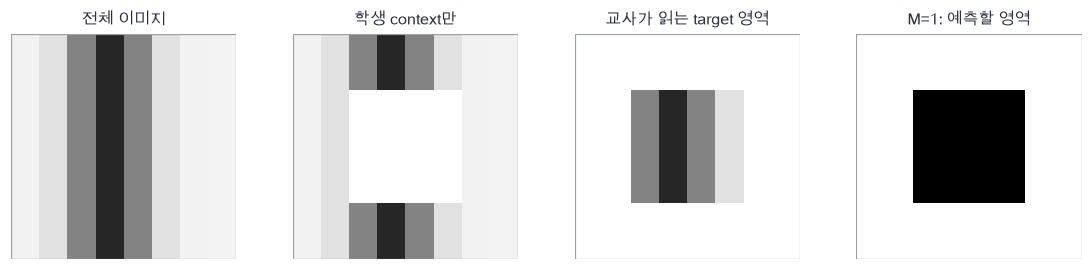

In [3]:
plot_images([preview,context_image,target_image,pixel_region],['전체 이미지','학생 context만','교사가 읽는 target 영역','M=1: 예측할 영역'])

🔍 **확인** · 그림의 흰 가림은 표시용입니다. 학생은 context 위치만 gather합니다. teacher는 전체 이미지의 patch 특징을 만들지만 loss는 target 영역만 선택합니다.

In [4]:
def patchify(images,patch=2):
    """(N,H,W)를 행 우선 patch (N,P,Q)로 바꿉니다. H,W는 patch의 배수입니다."""
    n,h,w=images.shape
    assert h%patch==0, '높이는 patch 크기의 배수여야 합니다'
    assert w%patch==0, '너비는 patch 크기의 배수여야 합니다'
    return images.reshape(n,h//patch,patch,w//patch,patch).transpose(0,1,3,2,4).reshape(n,-1,patch*patch)

In [5]:
def unpatchify(tokens,height=8,width=8,patch=2):
    """patchify의 역순 transpose·reshape로 원래 화소를 복원합니다."""
    return tokens.reshape(len(tokens),height//patch,width//patch,patch,patch).transpose(0,1,3,2,4).reshape(len(tokens),height,width)

In [6]:
def block_regions(n,rng):
    """4×4 patch 격자에서2×2 target block을 고르고 나머지12개를 context로 둡니다."""
    mask=np.zeros((n,16))
    ids=[]
    for i in range(n):
        row,col=rng.integers(0,3,size=2)
        target=np.array([4*(row+r)+col+c for r in range(2) for c in range(2)])
        mask[i,target]=1.
        ids.append(np.flatnonzero(mask[i]==0))
    return np.array(ids),mask

In [7]:
context_ids,region_mask=block_regions(4,np.random.default_rng(436))
np.testing.assert_array_equal(region_mask.sum(axis=1),4.)  # 검산: target patch4개
np.testing.assert_array_equal(region_mask[np.arange(4)[:,None],context_ids],0.)  # 검산: context·target 겹침0
assert context_ids.shape==(4,12), 'context는 이미지마다12개여야 합니다'
small=np.arange(16.).reshape(1,4,4)
np.testing.assert_array_equal(unpatchify(patchify(small),4,4),small)  # 검산: patch 왕복
print('context·target 분리와 patch 순서를 확인했습니다.')

context·target 분리와 patch 순서를 확인했습니다.


### ✏️ 연습 1 · target 영역만 고르기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

values:(N,P,D)에서 target mask 위치만 남기세요.

In [8]:
def exercise_region_mask(values,mask):
    """values:(N,P,D)에서 target mask 위치만 남기세요."""

    ### 구현할 내용: values:(N,P,D)에서 target mask 위치만 남기세요.
    raise NotImplementedError
    return selected

In [9]:
def check_region_mask(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[[1.,2.],[3.,4.]]]),np.array([[0.,1.]])),[[[0.,0.],[3.,4.]]])  # 검산: 두 번째 위치만
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_region_mask,exercise_region_mask,hint="values:(N,P,D)에서 target mask 위치만 남기세요.")

☐ exercise_region_mask: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: values:(N,P,D)에서 target mask 위치만 남기세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
selected = values*mask[:,:,None]
```

</details>

## 🔑 2. 같은 위치를 화소 또는 표현으로 맞힙니다

**이 절에서 가져갈 것:** 타깃의 종류가 달라지면 손실 단위와 해석도 달라집니다.

같은 가린 띠 영역에 두 종류의 정답을 만듭니다. pixel 목적은 원본4화소, latent 목적은 teacher의8차원 특징입니다.

> **용어** · **표현 타깃(latent target)**은 teacher가 원본에서 계산한 특징입니다. 의미 있는 특징이라고 미리 보장하지 않습니다. **위치 조건**은 어떤 target 위치를 예측하는지 predictor에 알려 주는 벡터입니다.

context encoder $h_{nk}=\tanh(X_{n,ids_k}W+b+E_{ids_k})$, $g_n=\operatorname{mean}_k h_{nk}$를 씁니다. predictor는 $r_{nj}=\tanh(g_nD+R_j+M_{nj}m)$, $P_{nj}=r_{nj}O+c$입니다. pixel이면 O:(8,4), latent면 O:(8,8)입니다. teacher는
$$T_{nj}=\tanh(X_{nj}W_\xi+b_\xi+E_{\xi,j})$$
로 모든 patch의 특징을 계산합니다. 이 작은 teacher는 patch끼리 attention을 하지 않는 **국소 특징**이며 원문 ViT의 문맥화된 특징과 다릅니다.

$$L_{pixel}=\frac{\sum M(P-X)^2}{2Q\sum M},\qquad L_{latent}=\frac{\sum M(P-\mathrm{sg}(T))^2}{2H\sum M}.$$

분모는 해당 target의 좌표 수 Q=4 또는 H=8입니다. latent target은 정규화하지 않은 tanh 특징입니다. **두 손실의 숫자를 직접 크기 순위로 비교하지 않습니다.** teacher의 크기가 줄어도 latent loss가 내려갈 수 있습니다. 빈 target mask는 손실·미분0이며 평가할 위치가 없다는 뜻입니다.

In [10]:
demo_pixels=np.array([[.2,.8,.2,.8],[.8,.8,.2,.2]])
demo_w=np.array([[.2,-.1],[.1,.2],[-.2,.1],[-.1,-.2]])
demo_pos=np.array([[.1,0.],[0.,.1]])
demo_latent=np.tanh(demo_pixels@demo_w+demo_pos)
demo_units=np.array([[4.,8.],[8.,16.]])

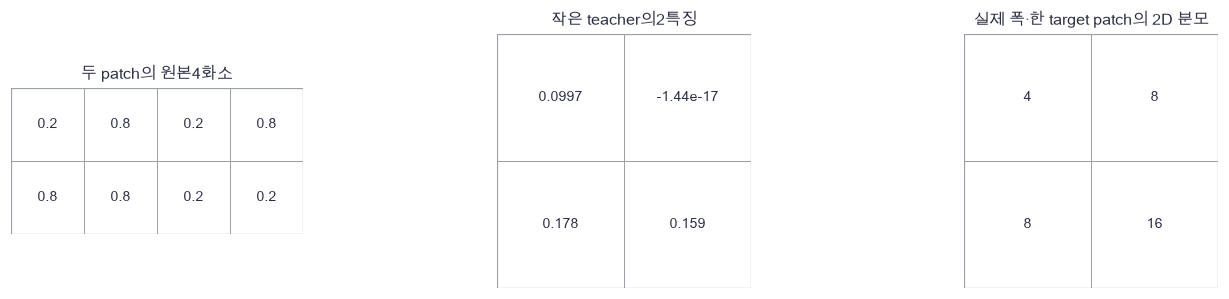

In [11]:
plot_panels([demo_pixels,demo_latent,demo_units],['두 patch의 원본4화소','작은 teacher의2특징','실제 폭·한 target patch의 2D 분모'])

🔍 **확인** · 그림의 teacher는 손계산용2특징입니다. 실제 실험은8특징입니다. 같은 원본이라도 teacher 가중치·위치가 바뀌면 타깃 숫자도 달라집니다. 오른쪽은 설명용 폭 표이므로 다음 검산에서 분모를 직접 확인합니다.

In [12]:
def init_masked(seed=420,patches=16,pixels=4,hidden=8):
    """visible encoder·위치·mask token·decoder의 모든 배열을 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.2,(pixels,hidden)),'b':np.zeros(hidden),
            'E':rng.normal(0,.1,(patches,hidden)),'D':rng.normal(0,.2,(hidden,hidden)),
            'R':rng.normal(0,.1,(patches,hidden)),'m':np.zeros(hidden),
            'O':rng.normal(0,.2,(hidden,pixels)),'c':np.zeros(pixels)}

In [13]:
def init_objectives(seed=430):
    """동일 context encoder·중간 predictor, 서로 다른 출력폭의 두 모델을 만듭니다."""
    pixel=init_masked(seed)
    latent={k:a.copy() for k,a in pixel.items()}
    rng=np.random.default_rng(seed+1)
    latent['O']=rng.normal(0,.2,(8,8))
    latent['c']=np.zeros(8)
    return pixel,latent

In [14]:
def teacher_features(X,target):
    """전체 이미지 각 patch를 teacher로 encode합니다. (N,P,Q) → (N,P,H)."""
    return np.tanh(X@target['W']+target['b']+target['E'][None,:,:])

In [15]:
def masked_loss(prediction,target,mask):
    """가린 화소만 반 제곱오차 평균. 빈 mask이면 손실·미분0으로 정합니다."""
    count=mask.sum()*prediction.shape[-1]
    if count==0:
        return 0.,np.zeros_like(prediction)
    residual=prediction-target
    gradient=residual*mask[:,:,None]/count
    return .5*np.sum(residual**2*mask[:,:,None])/count,gradient

In [16]:
pixel_example=np.ones((1,2,4))
latent_example=np.ones((1,2,8))
unit_mask=np.array([[0.,1.]])
pixel_loss,pixel_g=masked_loss(pixel_example,np.zeros_like(pixel_example),unit_mask)
latent_loss,latent_g=masked_loss(latent_example,np.zeros_like(latent_example),unit_mask)
np.testing.assert_allclose(pixel_loss,.5)  # 검산: 네 좌표의 평균 제곱오차 반
np.testing.assert_allclose(latent_loss,.5)  # 검산: 여덟 좌표의 평균 제곱오차 반
np.testing.assert_allclose(pixel_g[0,1],.25)  # 검산: Q=4 미분 분모
np.testing.assert_allclose(latent_g[0,1],.125)  # 검산: H=8 미분 분모
print('목적마다 좌표 수로 평균하는 분모를 확인했습니다.')

목적마다 좌표 수로 평균하는 분모를 확인했습니다.


### ✏️ 연습 2 · 고정 표현 타깃의 미분

target mask가 비어 있지 않을 때 fixed teacher target에 대한 예측 미분을 반환하세요.

In [17]:
def exercise_latent_residual(prediction,target,mask):
    """target mask가 비어 있지 않을 때 fixed teacher target에 대한 예측 미분을 반환하세요."""
    count = mask.sum()*prediction.shape[-1]
    ### 구현할 내용: target mask가 비어 있지 않을 때 fixed teacher target에 대한 예측 미분을 반환하세요.
    raise NotImplementedError
    return gradient

In [18]:
def check_latent_residual(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[3.,5.],[1.,1.]]]),np.array([[[1.,1.],[9.,9.]]]),np.array([[1.,0.]])),[[[1.,2.],[0.,0.]]])  # 검산: target 두 특징만 평균
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_latent_residual,exercise_latent_residual,hint="target mask가 비어 있지 않을 때 fixed teacher target에 대한 예측 미분을 반환하세요.")

☐ exercise_latent_residual: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: target mask가 비어 있지 않을 때 fixed teacher target에 대한 예측 미분을 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = (prediction-target)*mask[:,:,None]/count
```

</details>

## 🔑 3. 학생의 전 경로만 미분하고 타깃은 고정합니다

**이 절에서 가져갈 것:** target을 한 번 계산한 뒤 context encoder와 predictor의 전 원소를 검산합니다.

가린 화소를 학생이 읽으면 예측 과제가 무너집니다. 한 step의 teacher target은 복사해 고정하고, 학생 입력 경로에 target 화소의 기울기가 없는지 검사합니다.

$G=dP$에서 $dO=\sum r^TG$, $dc=\sum G$, $dU=(GO^T)\odot(1-r^2)$, $a=\sum_jdU$입니다. $dD=g^Ta$, $dR=\sum_ndU$, $dm=\sum_{n,j}M dU$, $dg=aD^T$를 구합니다. $dh=dg/K$, $dA=dh\odot(1-h^2)$ 뒤 $dW=\sum X_v^TdA$, $db=\sum dA$이고 $dE,dX$는 context ids로 누적합니다.

teacher encoder를 backward하지 않습니다. target값을 매 수치미분마다 다시 계산하면 다른 함수를 검사하는 것이므로 fixed target을 바깥에서 한 번 만들고 online 전체 파라미터와 입력만 차분합니다. teacher가 실제로 입력을 읽는 forward와 학생의 backward 경로를 구분하세요.

> **코드** · `np.add.at`은 같은 위치를 여러 이미지에서 써도 기여를 모두 더합니다. target을 `.copy()`한 것은 값의 독립성을 위한 것이고, stop-gradient는 teacher backward를 호출하지 않는 수동 규약입니다.

In [19]:
path_input=np.array([[[1.],[2.],[3.],[4.]]])
path_ids=np.array([[0,3]])
path_visible=path_input[np.arange(1)[:,None],path_ids]
path_contrib=np.array([[[.2],[.3]]])
path_scatter=np.zeros_like(path_input)
np.add.at(path_scatter,(np.arange(1)[:,None],path_ids),path_contrib)

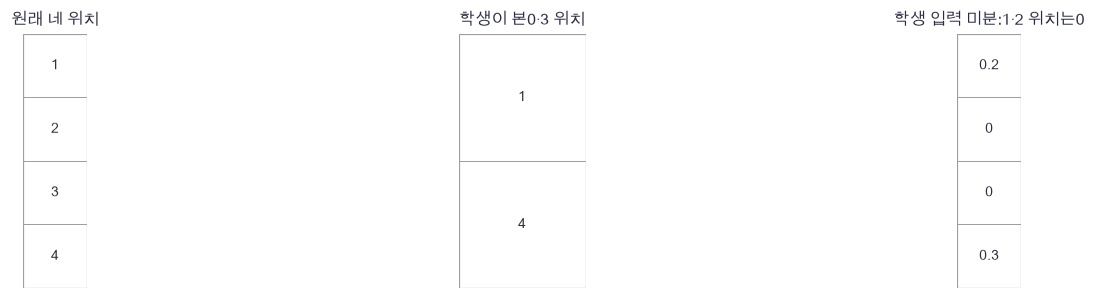

In [20]:
plot_panels([path_input[0],path_visible[0],path_scatter[0]],['원래 네 위치','학생이 본0·3 위치','학생 입력 미분:1·2 위치는0'])

🔍 **확인** · target 영역1·2는 teacher의 forward에서 읽을 수 있지만 이 학생 입력 미분 경로에는 들어가지 않습니다.

In [21]:
def masked_forward(X,ids,mask,p):
    """visible patch만 encode하고 context·위치·mask token으로 전체 patch를 예측합니다."""
    assert ids.shape[1]>0, 'visible patch가 최소1개 있어야 합니다'
    visible=X[np.arange(len(X))[:,None],ids]
    H=np.tanh(visible@p['W']+p['b']+p['E'][ids])
    context=H.mean(axis=1)
    decoder=np.tanh((context@p['D'])[:,None,:]+p['R'][None,:,:]+mask[:,:,None]*p['m'])
    prediction=decoder@p['O']+p['c']
    return prediction,(X.shape,ids,mask,visible,H,context,decoder)

In [22]:
def masked_backward(G,cache,p):
    """decoder·풀링·gather를 거꾸로 따라 모든 파라미터와 입력을 미분합니다."""
    # 1. 출력과 위치·mask token의 모든 관측·patch 기여를 더합니다.
    shape,ids,mask,visible,H,context,decoder=cache
    n,k,h=H.shape
    dU=(G@p['O'].T)*(1-decoder**2)
    pooled=dU.sum(axis=1)
    grads={'O':decoder.reshape(-1,h).T@G.reshape(-1,G.shape[-1]),'c':G.sum(axis=(0,1)),
           'D':context.T@pooled,'R':dU.sum(axis=0),'m':(dU*mask[:,:,None]).sum(axis=(0,1))}
    # 2. 평균 context를 visible 원소에 나누고 위치 인덱스로 누적합니다.
    dH=np.repeat((pooled@p['D'].T)[:,None,:]/k,k,axis=1)
    dA=dH*(1-H**2)
    grads['W']=visible.reshape(-1,visible.shape[-1]).T@dA.reshape(-1,h)
    grads['b']=dA.sum(axis=(0,1))
    grads['E']=np.zeros_like(p['E'])
    np.add.at(grads['E'],ids,dA)
    dX=np.zeros(shape)
    np.add.at(dX,(np.arange(n)[:,None],ids),dA@p['W'].T)
    return grads,dX

In [23]:
# 쓰는 것: init_masked (2절) · masked_loss (2절) · teacher_features (2절)
probe=init_masked(437,patches=4,pixels=1,hidden=2)
probe['O']=np.array([[.2,.1],[-.1,.3]])
probe['c']=np.zeros(2)
probe_x=np.random.default_rng(438).normal(size=(2,4,1))
probe_ids=np.array([[0,3],[1,2]])
probe_mask=np.ones((2,4))
probe_mask[np.arange(2)[:,None],probe_ids]=0.
probe_teacher={k:probe[k].copy() for k in ['W','b','E']}
frozen_target=teacher_features(probe_x,probe_teacher).copy()
probe_p,probe_cache=masked_forward(probe_x,probe_ids,probe_mask,probe)
_,probe_G=masked_loss(probe_p,frozen_target,probe_mask)
analytic,analytic_x=masked_backward(probe_G,probe_cache,probe)

In [24]:
def frozen_objective():
    """이번 step의 교사 타깃을 고정한 학생 목적입니다."""
    # 쓰는 것: masked_loss (2절)
    P,_=masked_forward(probe_x,probe_ids,probe_mask,probe)
    return masked_loss(P,frozen_target,probe_mask)[0]

In [25]:
errors=[]
for key in probe:
    numeric=numerical_gradient(frozen_objective,probe[key])
    np.testing.assert_allclose(analytic[key],numeric,atol=2e-8,rtol=3e-5)  # 검산: 전체 online 파라미터
    errors.append(np.max(np.abs(analytic[key]-numeric)))
numeric_x=numerical_gradient(frozen_objective,probe_x)
np.testing.assert_allclose(analytic_x,numeric_x,atol=2e-8,rtol=3e-5)  # 검산: 모든 학생 입력 원소
np.testing.assert_array_equal(analytic_x[probe_mask.astype(bool)],0.)  # 검산: target 화소 입력 경로0
for key in probe_teacher:
    np.testing.assert_allclose(numerical_gradient(frozen_objective,probe_teacher[key]),0.)  # 검산: 고정 목적은 teacher를 재계산하지 않음
print('전체 학생 미분 최대 절대오차',max(errors+[np.max(np.abs(analytic_x-numeric_x))]))

전체 학생 미분 최대 절대오차 3.113756756774333e-12


In [26]:
# 쓰는 것: masked_forward (3절)
modified=probe_x.copy()
modified[probe_mask.astype(bool)]+=100.
unchanged_prediction,_=masked_forward(modified,probe_ids,probe_mask,probe)
np.testing.assert_array_equal(unchanged_prediction,probe_p)  # 검산: target 입력 변경이 학생 예측에 누출되지 않음
print('학생 입력과 교사 타깃의 정보 경계를 확인했습니다.')
try:
    masked_forward(probe_x,np.empty((2,0),dtype=int),np.ones((2,4)),probe)
except AssertionError:
    print("빈 context ids는 forward에서도 거부합니다.")
else:
    raise AssertionError("빈 context 입력은 거부되어야 합니다")

학생 입력과 교사 타깃의 정보 경계를 확인했습니다.
빈 context ids는 forward에서도 거부합니다.


### ✏️ 연습 3 · context 평균의 역전파

이미지별 context 평균의 상류 G:(N,H)를 K개 patch에 나누세요.

In [27]:
def exercise_context_gradient(G,K):
    """이미지별 context 평균의 상류 G:(N,H)를 K개 patch에 나누세요."""

    ### 구현할 내용: 이미지별 context 평균의 상류 G:(N,H)를 K개 patch에 나누세요.
    raise NotImplementedError
    return dH

In [28]:
def check_context_gradient(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[4.,-2.]]),2),[[[2.,-1.],[2.,-1.]]])  # 검산: context 두 patch에 나누기
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_context_gradient,exercise_context_gradient,hint="이미지별 context 평균의 상류 G:(N,H)를 K개 patch에 나누세요.")

☐ exercise_context_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 이미지별 context 평균의 상류 G:(N,H)를 K개 patch에 나누세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dH = np.repeat(G[:,None,:]/K,K,axis=1)
```

</details>

## 🔑 4. EMA와 위치만 남는 붕괴를 구분합니다

**이 절에서 가져갈 것:** 위치별로 다른 특징이라도 같은 위치에서 모든 이미지가 같으면 내용 정보가 없습니다.

위치 벡터만 맞히는 predictor는 이미지가 달라도 비슷한 답을 낼 수 있습니다. patch 전체를 섞어 분산을 재면 위치 차이 때문에 분산이 커 보일 수 있습니다.

teacher 갱신은 online Adam **뒤** $\xi\leftarrow.99\xi+.01\theta^{enc}$이며 대상은 W,b,E뿐입니다. predictor D,R,m,O,c는 teacher에 없습니다. m=0은 바로복사, m=1은고정입니다.

> **용어** · **위치 조건부 분산**은 각 patch 위치 j를 고정한 채 서로 다른 이미지 n 사이에서 특징이 바뀌는 정도입니다. 여기서는 `T.var(axis=0)`이 (P,H)로 이를 계산합니다.

$T_{nj}=e_j$처럼 위치만 남으면 전체 NP축을 섞은 분산은 양수일 수 있지만 모든 j에서 $\operatorname{Var}_n(T_{nj})=0$입니다. predictor도 같은 e_j를 내면 latent loss는0입니다. 따라서 목적 감소·전체 분산만으로 내용 표현을 배웠다고 주장하지 않습니다. 41번의 분산 제약은 여기서 자동으로 추가하지 않았고, 현재 모델의 붕괴 가능성을 그대로 관찰합니다.

In [29]:
position_codes=np.array([[0.,0.],[1.,0.],[0.,1.],[1.,1.]])
position_only=np.repeat(position_codes[None,:,:],3,axis=0)
position_statistics=np.array([[position_only.reshape(-1,2).var(axis=0).mean(),position_only.var(axis=0).mean()]])
ema_example=np.array([[0.,2.],[2.,4.],[.2,2.2]])

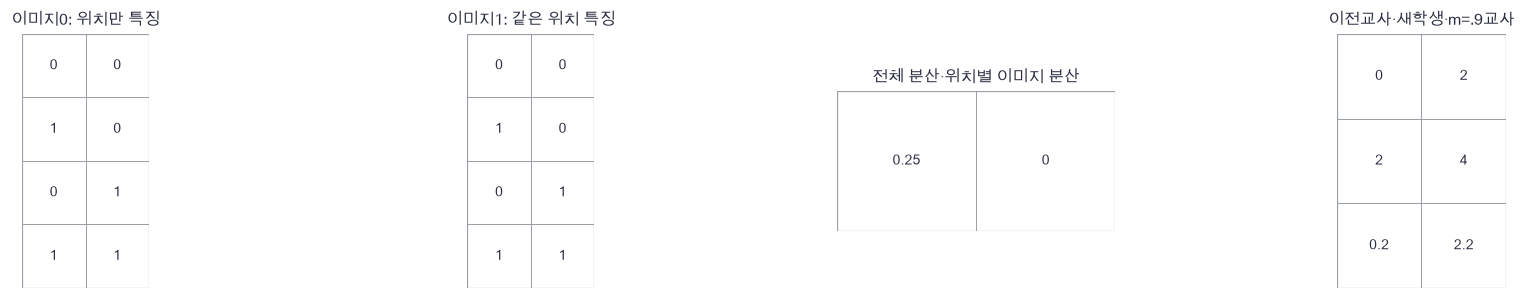

In [30]:
plot_panels([position_only[0],position_only[1],position_statistics,ema_example],['이미지0: 위치만 특징','이미지1: 같은 위치 특징','전체 분산·위치별 이미지 분산','이전교사·새학생·m=.9교사'])

🔍 **확인** · 두 이미지의 각 위치 특징은 완전히 같습니다. patch 위치를 섞은 분산.25가 이미지 내용의 구분을 뜻하지 않습니다.

In [31]:
def update_teacher(target,online,momentum=.99):
    """online 갱신 뒤 encoder W,b,E만 EMA합니다. predictor는 포함하지 않습니다."""
    for key in target:
        target[key]=momentum*target[key]+(1-momentum)*online[key]

In [32]:
def adam_step(p,g,m,v,step,lr=.01):
    """Adam 모멘트·bias 보정을 적용합니다."""
    for k in p:
        m[k]=.9*m[k]+.1*g[k]
        v[k]=.999*v[k]+.001*g[k]**2
        p[k]-=lr*(m[k]/(1-.9**step))/(np.sqrt(v[k]/(1-.999**step))+1e-8)

In [33]:
# 쓰는 것: masked_loss (2절) · position_only (4절)
zero_value,zero_gradient=masked_loss(position_only,position_only,np.ones((3,4)))
np.testing.assert_allclose(zero_value,0.)  # 검산: 위치만 맞혀도 예측 목적0
np.testing.assert_allclose(position_only.var(axis=0),0.)  # 검산: 같은 위치의 이미지 구분 없음
target={'W':np.array([[0.,2.]])}
online={'W':np.array([[2.,4.]]),'O':np.eye(2)}
update_teacher(target,online,.9)
np.testing.assert_allclose(target['W'],[[.2,2.2]])  # 검산: .9old+.1new
assert set(target)=={'W'}, 'teacher에 predictor가 복사되지 않아야 합니다'
for momentum,expected in [(0.,online['W']),(1.,np.array([[0.,2.]]))]:
    check_target={'W':np.array([[0.,2.]])}
    update_teacher(check_target,online,momentum)
    np.testing.assert_allclose(check_target['W'],expected)  # 검산: EMA 양 끝값
print('위치만 남는 해와 EMA 대상·양 끝값을 확인했습니다.')

위치만 남는 해와 EMA 대상·양 끝값을 확인했습니다.


In [34]:
# 쓰는 것: probe, probe_teacher, analytic (3절) · adam_step, update_teacher (4절)
step_online={k:a.copy() for k,a in probe.items()}
step_teacher={k:a.copy() for k,a in probe_teacher.items()}
teacher_before={k:a.copy() for k,a in step_teacher.items()}
step_m={k:np.zeros_like(a) for k,a in step_online.items()}
step_v={k:np.zeros_like(a) for k,a in step_online.items()}
adam_step(step_online,analytic,step_m,step_v,1,lr=.005)
for key in step_teacher:
    np.testing.assert_array_equal(step_teacher[key],teacher_before[key])  # 검산: online optimizer는 teacher 불변
update_teacher(step_teacher,step_online,.99)
for key in step_teacher:
    np.testing.assert_allclose(step_teacher[key],.99*teacher_before[key]+.01*step_online[key])  # 검산: 갱신 뒤 online encoder를 EMA
print('실제 한 step의 optimizer→EMA 순서를 확인했습니다.')

실제 한 step의 optimizer→EMA 순서를 확인했습니다.


### ✏️ 연습 4 · 같은 위치에서 이미지를 비교하기

T:(N,P,H)의 관측 축만으로 위치별 특징 분산 (P,H)을 계산하세요.

In [35]:
def exercise_conditional_variance(T):
    """T:(N,P,H)의 관측 축만으로 위치별 특징 분산 (P,H)을 계산하세요."""

    ### 구현할 내용: T:(N,P,H)의 관측 축만으로 위치별 특징 분산 (P,H)을 계산하세요.
    raise NotImplementedError
    return variance

In [36]:
def check_conditional_variance(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[0.],[10.]],[[2.],[10.]]])),[[1.],[0.]])  # 검산: 첫 위치만 이미지별 변화
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_conditional_variance,exercise_conditional_variance,hint="T:(N,P,H)의 관측 축만으로 위치별 특징 분산 (P,H)을 계산하세요.")

☐ exercise_conditional_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: T:(N,P,H)의 관측 축만으로 위치별 특징 분산 (P,H)을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
variance = T.var(axis=0)
```

</details>

## 🔑 5. 같은 자료에서 두 목적을 실제로 학습합니다

**이 절에서 가져갈 것:** 공통 예산·분할을 유지하되 다른 타깃 단위의 손실을 성능 순위로 비교하지 않습니다.

42번과 같은8×8 띠 생성 규칙을 새 독립 분할로 만듭니다. train256/valid64/test128(seed431/432/433), 초기430, batch난수434, block난수435를 고정합니다. pixel·latent 모델은 **같은 encoder W,b,E와 중간 predictor D,R,m 초기값**을 공유하고 출력 폭만4·8로 다릅니다. 출력 head 파라미터가 달라 전체 파라미터 예산이 같지는 않습니다. 표에서 실제 개수를 계산합니다.

두 조건 모두500갱신, batch32, Adam lr.005, context12patch/target4patch입니다. Adam은 .9/.999 모멘트와 bias 보정·epsilon1e−8을 씁니다. latent teacher는 같은 encoder 복사에서 출발해 Adam 뒤 EMA .99로 갱신합니다. valid block(seed439)과test block(seed440)을 고정하며 조건마다 같습니다. validation은 관찰만 하고 선택에 쓰지 않으며 평가 후 설정을 바꾸지 않습니다. label은 표현 학습에 전달하지 않습니다.

학습 후 두 online encoder에서 모든 patch를 보인 평균 context g를 추출합니다. **E 위치 정보는 포함되지만 평균 압축은 공간 정보를 제한합니다. predictor 위치 R이 이 손실을 자동 복구하지 않습니다.** 같은 초기 encoder도 기준으로 평가합니다. encoder를 동결하고 train 방향라벨의2클래스 선형 probe를0초기·300전배치 SGD lr.15로 학습합니다. CE미분 `(softmax-onehot)/N`이며 test분모128입니다. 이 고정 probe는 표현 크기·최적화 예산의 영향도 받습니다.

공통 표는 probe정확도·context 평균·분산·다른 이미지 거리입니다. pixel 복원 오차와 latent의 현재teacher/초기teacher 오차는 별도 출력합니다. teacher의 위치별 이미지 분산도 초기와 마지막을 비교합니다. 한 seed·작은 구조의 결과를 원논문의 품질로 일반화하지 않습니다.

> **코드** · 사전 사본은 공유 초기값을 보존합니다. 배치 `integers`는 복원추출입니다. `np.roll`은 다른 이미지 쌍을 고정하는 순환이동입니다. teacher 초기값은 별도로 보관해 움직이는 타깃의 진단에 씁니다.

In [37]:
budget=np.array([[256,431],[64,432],[128,433]])
view_sizes=np.array([[12,4,4],[12,4,8]])
same_state=np.array([[430.,434.,435.],[430.,434.,435.]])

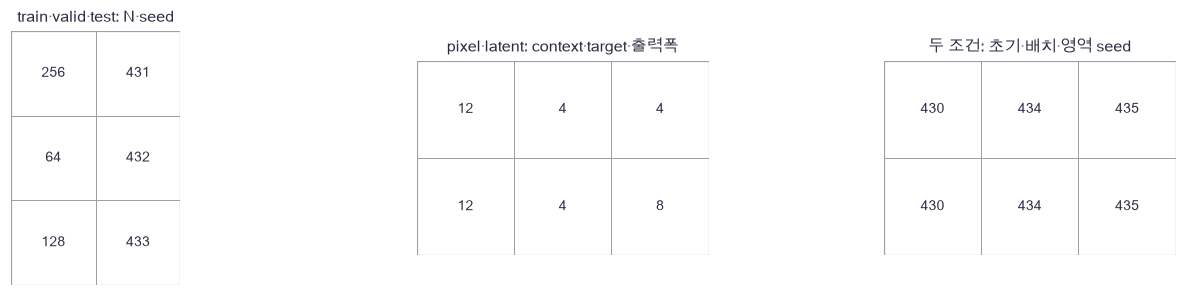

In [38]:
plot_panels([budget,view_sizes,same_state],['train·valid·test: N·seed','pixel·latent: context·target·출력폭','두 조건: 초기·배치·영역 seed'])

🔍 **확인** · 출력 폭이 다르므로 파라미터 수와 손실 단위는 다릅니다. 같은 분할·block·갱신으로 목적 차이를 관찰하지만 완전히 동일한 모델 크기 실험이라고 부르지 않습니다.

In [39]:
def make_images(n,seed):
    """가로·세로의 매끄러운 띠 이미지를 생성합니다. (N,8,8), orientation:(N,)."""
    rng=np.random.default_rng(seed)
    labels=rng.integers(0,2,n)
    center=rng.uniform(2.,5.,n)
    intensity=rng.uniform(.5,.9,n)
    row,col=np.mgrid[:8,:8]
    coord=np.where(labels[:,None,None]==0,col[None,:,:],row[None,:,:])
    images=.05+intensity[:,None,None]*np.exp(-.5*((coord-center[:,None,None])/.9)**2)
    images+=rng.normal(0,.015,images.shape)
    return np.clip(images,0.,1.),labels

In [40]:
def train_objective(X,valid_X,valid_ids,valid_mask,initial,kind):
    """동일 batch·block 난수·500갱신의 pixel 또는 latent 예측 학습입니다."""
    # 쓰는 것: adam_step (4절) · block_regions (1절) · masked_backward (3절) · masked_forward (3절) · masked_loss (2절) · teacher_features (2절) · update_teacher (4절)
    # 1. 공통 encoder 초기값과 별도 optimizer·teacher 상태입니다.
    p={k:a.copy() for k,a in initial.items()}
    target={k:p[k].copy() for k in ['W','b','E']}
    m={k:np.zeros_like(a) for k,a in p.items()}
    v={k:np.zeros_like(a) for k,a in p.items()}
    batch_rng=np.random.default_rng(434)
    region_rng=np.random.default_rng(435)
    history=[]
    # 2. target 값은 먼저 고정하고 online backward 후에만 EMA합니다.
    for step in range(1,501):
        idx=batch_rng.integers(0,len(X),32)
        ids,mask=block_regions(32,region_rng)
        fixed=X[idx].copy() if kind=='pixel' else teacher_features(X[idx],target).copy()
        prediction,cache=masked_forward(X[idx],ids,mask,p)
        loss,G=masked_loss(prediction,fixed,mask)
        grads,_=masked_backward(G,cache,p)
        adam_step(p,grads,m,v,step,lr=.005)
        if kind=='latent':
            update_teacher(target,p,.99)
        if step%50==0:
            valid_target=valid_X if kind=='pixel' else teacher_features(valid_X,target)
            estimate,_=masked_forward(valid_X,valid_ids,valid_mask,p)
            history.append([step,masked_loss(estimate,valid_target,valid_mask)[0]])
    return p,target,np.array(history)

In [41]:
def all_visible_features(X,p):
    """평가용 encoder의 모든 patch 평균. decoder·mask token은 사용하지 않습니다."""
    H=np.tanh(X@p['W']+p['b']+p['E'][None,:,:])
    return H.mean(axis=1)

In [42]:
def multiclass_loss(logits,y):
    """안정적인 표본 평균 CE와 logit 미분. (N,C), (N,) → scalar,(N,C)."""
    shifted=logits-logits.max(axis=1,keepdims=True)
    expS=np.exp(shifted)
    P=expS/expS.sum(axis=1,keepdims=True)
    loss=np.mean(np.log(expS.sum(axis=1))-shifted[np.arange(len(y)),y])
    G=P.copy()
    G[np.arange(len(y)),y]-=1
    return loss,G/len(y)

In [43]:
def fit_probe(features,y):
    """고정 표현 위의 선형 2클래스 probe만 300회 전배치 SGD 학습합니다."""
    W=np.zeros((features.shape[1],2))
    b=np.zeros(2)
    for step in range(300):
        loss,G=multiclass_loss(features@W+b,y)
        W-=.15*features.T@G
        b-=.15*G.sum(axis=0)
    return W,b

In [44]:
# 쓰는 것: block_regions (1절) · init_objectives (2절) · make_images (5절) · patchify (1절) · train_objective (5절)
train_images,train_y=make_images(256,431)
valid_images,valid_y=make_images(64,432)
test_images,test_y=make_images(128,433)
train_x=patchify(train_images)
valid_x=patchify(valid_images)
test_x=patchify(test_images)
valid_ids,valid_mask=block_regions(64,np.random.default_rng(439))
test_ids,test_mask=block_regions(128,np.random.default_rng(440))
initial_pixel,initial_latent=init_objectives(430)
initial_teacher={k:initial_latent[k].copy() for k in ['W','b','E']}
pixel,pixel_target,pixel_history=train_objective(train_x,valid_x,valid_ids,valid_mask,initial_pixel,'pixel')
latent,teacher,latent_history=train_objective(train_x,valid_x,valid_ids,valid_mask,initial_latent,'latent')
print('학습 파라미터 pixel/latent',sum(a.size for a in pixel.values()),sum(a.size for a in latent.values()))
print('latent의 EMA teacher',sum(a.size for a in teacher.values()),'· 두 조건 모두500갱신')

학습 파라미터 pixel/latent 404 440
latent의 EMA teacher 168 · 두 조건 모두500갱신


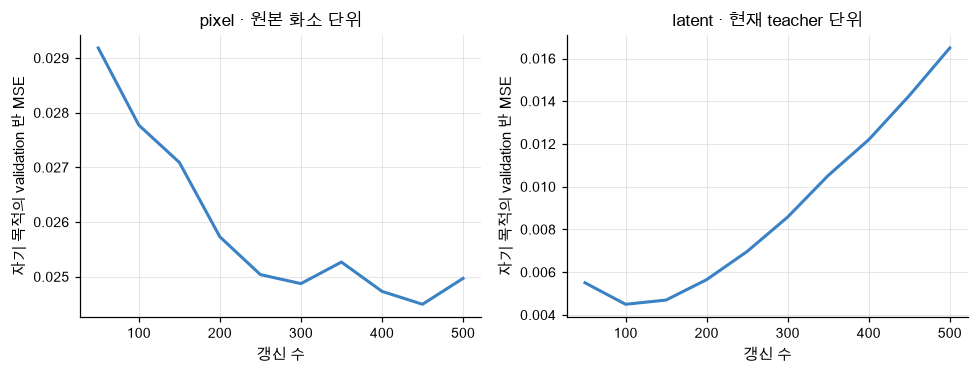

In [45]:
plot_objectives([pixel_history,latent_history],['pixel · 원본 화소 단위','latent · 현재 teacher 단위'])

In [46]:
# 쓰는 것: all_visible_features (5절)
report=[]
for p in [initial_pixel,pixel,latent]:
    frozen={k:a.copy() for k,a in p.items()}
    train_g=all_visible_features(train_x,p)
    test_g=all_visible_features(test_x,p)
    Wq,bq=fit_probe(train_g,train_y)
    accuracy=np.mean((test_g@Wq+bq).argmax(axis=1)==test_y)
    gap=((test_g-np.roll(test_g,1,axis=0))**2).sum(axis=1).mean()
    report.append([accuracy,test_g.mean(),test_g.var(axis=0).mean(),gap])
    for key in p:
        np.testing.assert_array_equal(p[key],frozen[key])  # 검산: probe 중 encoder·predictor 불변
report=np.array(report)
print('초기/pixel/latent · test probe정확도, context평균,분산,다른거리',np.round(report,6))

초기/pixel/latent · test probe정확도, context평균,분산,다른거리 [[ 5.23438e-01  1.74230e-02  1.95000e-04  3.51900e-03]
 [ 5.23438e-01  2.53070e-02  8.66000e-04  1.55800e-02]
 [ 5.23438e-01 -1.07867e-01  7.93000e-04  1.41690e-02]]


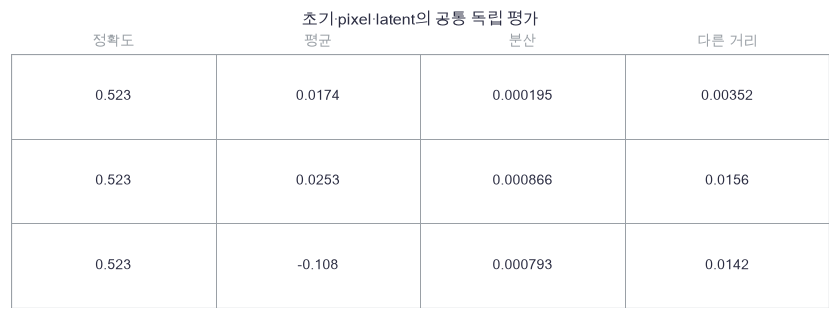

In [47]:
plot_panels([report],['초기·pixel·latent의 공통 독립 평가'],[['정확도','평균','분산','다른 거리']])

In [48]:
# 쓰는 것: init_objectives (2절) · initial_pixel (5절) · initial_teacher (5절) · latent (5절) · masked_forward (3절) · masked_loss (2절) · pixel (5절) · teacher (5절) · teacher_features (2절) · test_ids (5절) · test_mask (5절) · test_x (5절) · train_x (5절)
pixel_pred,_=masked_forward(test_x,test_ids,test_mask,pixel)
latent_pred,_=masked_forward(test_x,test_ids,test_mask,latent)
teacher_now=teacher_features(test_x,teacher)
teacher_initial=teacher_features(test_x,initial_teacher)
pixel_error=masked_loss(pixel_pred,test_x,test_mask)[0]
latent_error=masked_loss(latent_pred,teacher_now,test_mask)[0]
fixed_teacher_error=masked_loss(latent_pred,teacher_initial,test_mask)[0]
train_mean=np.repeat(train_x.mean(axis=0,keepdims=True),len(test_x),axis=0)
mean_error=masked_loss(train_mean,test_x,test_mask)[0]
content_variances=np.array([[teacher_initial.var(axis=0).mean(),teacher_now.var(axis=0).mean()]])
print('pixel 반MSE / train평균이미지 반MSE',pixel_error,mean_error)
print('latent 현재teacher / 초기고정teacher 반MSE',latent_error,fixed_teacher_error)
print('teacher 같은 위치의 이미지별 분산: 초기→마지막',content_variances[0])
np.testing.assert_array_equal(initial_pixel['W'],init_objectives(430)[0]['W'])  # 검산: 초기 encoder 보존

pixel 반MSE / train평균이미지 반MSE 0.023624026923679077 0.026653243957594296
latent 현재teacher / 초기고정teacher 반MSE 0.015102003756083365 0.030232375399314487
teacher 같은 위치의 이미지별 분산: 초기→마지막 [0.00907372 0.03046551]


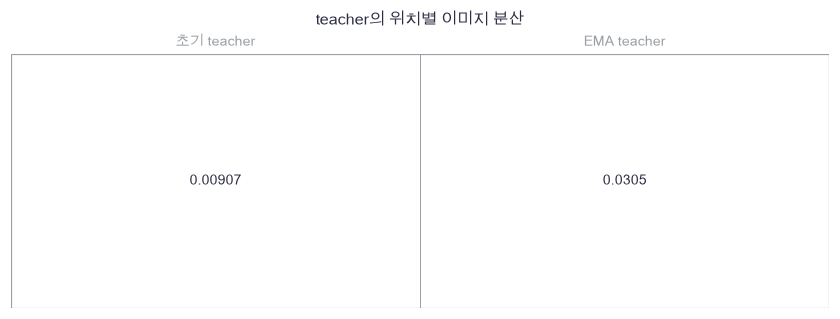

In [49]:
plot_panels([content_variances],['teacher의 위치별 이미지 분산'],[['초기 teacher','EMA teacher']])

In [50]:
# 쓰는 것: test_mask (5절) · test_x (5절) · unpatchify (1절)
shown=unpatchify(test_x*(1-test_mask[:,:,None]))[0]
pixel_prediction_image=unpatchify(pixel_pred)[0]
combined=test_x[:1]*(1-test_mask[:1,:,None])+pixel_pred[:1]*test_mask[:1,:,None]
combined_image=unpatchify(combined)[0]

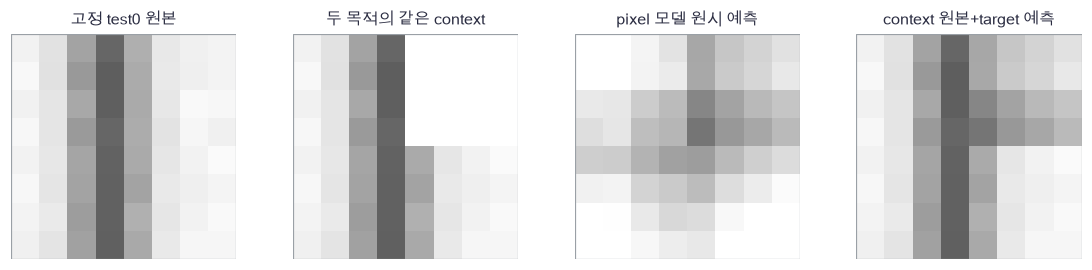

In [51]:
plot_images([test_images[0],shown,pixel_prediction_image,combined_image],['고정 test0 원본','두 목적의 같은 context','pixel 모델 원시 예측','context 원본+target 예측'])

🔍 **확인** · latent 모델은 화소 decoder가 없으므로 latent 출력을 이미지 복원으로 그리지 않습니다. pixel 원시 예측은0–1 표시 척도를 쓰지만 수치 오차는 clip 전 값입니다. 완성 그림의 context는 원본 복사입니다. 현재 teacher와의 오차가 작아져도 초기 teacher 오차·위치별 이미지 분산·동결 probe를 함께 보아야 합니다. 낮은 손실만으로 의미 있는 표현이나 붕괴 방지를 입증하지 않습니다. 이 고정 실행에서 두 학습 모델의 방향 probe는 초기와 같은 약.523이며 유용한 방향 표현의 개선을 확인하지 못했습니다. pixel 반 MSE는 약.0236으로 평균 이미지 기준선.0267보다 작지만 복원은 흐릿합니다. latent의 현재 teacher 오차는.0151, 초기 고정 teacher 오차는.0302이고, 위치별 이미지 분산은.0091에서.0305로 늘었습니다. 따라서 이 실행은 단순한 상수 붕괴로 설명되지는 않지만 좋은 의미 표현을 입증한 것도 아닙니다. 움직이는 teacher 때문에 validation 목적도 후반에 증가하며, 이를 숨기거나 설정을 다시 고르지 않습니다.

### ✏️ 연습 5 · 모든 patch로 고정 표현 읽기

decoder 없이 전체 patch encoder의 평균 context를 반환하세요.

In [52]:
def exercise_probe_mean(X,W,bias,E):
    """decoder 없이 전체 patch encoder의 평균 context를 반환하세요."""

    ### 구현할 내용: decoder 없이 전체 patch encoder의 평균 context를 반환하세요.
    raise NotImplementedError
    return features

In [53]:
def check_probe_mean(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.zeros((2,3,1)),np.zeros((1,2)),np.zeros(2),np.zeros((3,2))),np.zeros((2,2)))  # 검산: 모든 입력·위치0인 경우
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_probe_mean,exercise_probe_mean,hint="decoder 없이 전체 patch encoder의 평균 context를 반환하세요.")

☐ exercise_probe_mean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: decoder 없이 전체 patch encoder의 평균 context를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
features = np.tanh(X@W+bias+E[None,:,:]).mean(axis=1)
```

</details>

## ✏️ 끝 연습 · 타깃의 종류와 갱신 경계를 검사합니다

### ✏️ 연습 A · 교사만 EMA하기

encoder 배열 하나의 EMA를 계산하세요.

In [54]:
def exercise_teacher_ema(old,new,m):
    """encoder 배열 하나의 EMA를 계산하세요."""

    ### 구현할 내용: encoder 배열 하나의 EMA를 계산하세요.
    raise NotImplementedError
    return updated

In [55]:
def check_teacher_ema(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,2.]),np.array([2.,4.]),.99),[.02,2.02])  # 검산: 새 학생의1%
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_teacher_ema,exercise_teacher_ema,hint="encoder 배열 하나의 EMA를 계산하세요.")

☐ exercise_teacher_ema: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: encoder 배열 하나의 EMA를 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updated = m*old+(1-m)*new
```

</details>

### ✏️ 연습 B · 영역과 특징 수의 분모

latent 목적의 유효 좌표 수를 반환하세요.

In [56]:
def exercise_target_count(mask,features):
    """latent 목적의 유효 좌표 수를 반환하세요."""

    ### 구현할 내용: latent 목적의 유효 좌표 수를 반환하세요.
    raise NotImplementedError
    return count

In [57]:
def check_target_count(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_equal(candidate(np.array([[1.,0.,1.],[0.,1.,0.]]),8),24)  # 검산: target 세 위치×여덟 특징
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_target_count,exercise_target_count,hint="latent 목적의 유효 좌표 수를 반환하세요.")

☐ exercise_target_count: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: latent 목적의 유효 좌표 수를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
count = mask.sum()*features
```

</details>

### ✏️ 연습 C · 위치 평균을 뺀 내용 차이

각 target 위치에서 관측 평균을 빼어 위치 상수 성분을 제거하세요.

In [58]:
def exercise_content_variance(T):
    """각 target 위치에서 관측 평균을 빼어 위치 상수 성분을 제거하세요."""

    ### 구현할 내용: 각 target 위치에서 관측 평균을 빼어 위치 상수 성분을 제거하세요.
    raise NotImplementedError
    return centered

In [59]:
def check_content_variance(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[1.],[10.]],[[3.],[10.]]])),[[[-1.],[0.]],[[1.],[0.]]])  # 검산: 같은 위치에서 관측 평균 빼기
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_content_variance,exercise_content_variance,hint="각 target 위치에서 관측 평균을 빼어 위치 상수 성분을 제거하세요.")

☐ exercise_content_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 각 target 위치에서 관측 평균을 빼어 위치 상수 성분을 제거하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
centered = T-T.mean(axis=0,keepdims=True)
```

</details>

### ✏️ 연습 D · 표현 단위가 손실을 바꾸는 효과

두 표현을 같은 scale로 바꾼 전체 좌표 반 MSE를 계산하세요. 손실 크기의 단위 의존성을 확인합니다.

In [60]:
def exercise_feature_units(prediction,target,scale):
    """두 표현을 같은 scale로 바꾼 전체 좌표 반 MSE를 계산하세요. 손실 크기의 단위 의존성을 확인합니다."""

    ### 구현할 내용: 두 표현을 같은 scale로 바꾼 전체 좌표 반 MSE를 계산하세요. 손실 크기의 단위 의존성을 확인합니다.
    raise NotImplementedError
    return loss

In [61]:
def check_feature_units(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,1.]]),np.zeros((1,2)),2.),2.)  # 검산: 원래.5에서 scale²=4배
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_feature_units,exercise_feature_units,hint="두 표현을 같은 scale로 바꾼 전체 좌표 반 MSE를 계산하세요. 손실 크기의 단위 의존성을 확인합니다.")

☐ exercise_feature_units: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 두 표현을 같은 scale로 바꾼 전체 좌표 반 MSE를 계산하세요. 손실 크기의 단위 의존성을 확인합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = .5*np.mean((scale*(prediction-target))**2)
```

</details>

### ✏️ 준비도 질문

- **설명:** pixel과 latent target은 무엇이 다르며 teacher가 의미를 이미 안다고 가정하면 왜 안 되나요? → 1·2절
- **수식:** target mask·좌표 수 분모·stop-gradient·EMA의 순서를 쓸 수 있나요? → 2–4절
- **구현:** 고정 타깃 아래 모든 학생 배열·입력의 미분과 target 입력 누출0을 검산할 수 있나요? → 3절
- **변형 검산:** 위치만 남는 표현·특징 단위 변경·다른 target 크기에서 목적값과 정보량을 구분할 수 있나요? → 4·5절, 연습 A–D

### 📎 원전과 학습 경로

[I-JEPA 원논문, Assran et al., 2023](https://arxiv.org/abs/2301.08243)은 context block에서 target block들의 표현을 예측하며 영역 선택의 중요성을 다룹니다. 이 노트북은 shared patch tanh·평균 context·국소 teacher로 전체 계산을 드러냅니다. 원논문의 ViT·문맥화된 teacher·여러 큰 target block·성능 재현이 아닙니다. 38–43에서 바꾼 것은 변형, 쌍 목적, target 갱신, 통계 제약, 화소 타깃, 표현 타깃입니다. 구조와 목적을 따로 비교하는 습관을 유지하세요.